In [1]:
# Cell 2: Mục 13 - Classification Head
from pretrained_classification import inspect_classifier

inspect_classifier()

C:\Users\Acer\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[transformers] BertModel LOAD REPORT from: google/bert_uncased_L-2_H-128_A-2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
bert.pooler.dense.weight                   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
bert.pooler.dense.bias                     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


{
  "model": "google/bert_uncased_L-2_H-128_A-2",
  "revision": "30b0a37ccaaa32f332884b96992754e246e48c5f",
  "head": "Linear(in_features=128, out_features=2, bias=True)",
  "batch_size": 2,
  "logits_shape": [
    2,
    2
  ],
  "parameters": 4369666
}


In [2]:
# Cell 3: Mục 14 - Experiment 1: From Scratch vs Pretrained
import gc
import json
import platform
import random
import threading
from importlib.metadata import version
from time import perf_counter

import datasets
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
import torch
from datasets import load_dataset
from huggingface_hub import hf_hub_download
from IPython.display import display
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    confusion_matrix,
    precision_recall_fscore_support,
)
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

from pretrained_classification import (
    LABELS,
    LAB_DIR,
    MODEL_ID,
    MODEL_REVISION,
    SentimentClassifier,
    load_tokenizer,
)

SEED = 42
IMDB_ID = "stanfordnlp/imdb"
IMDB_REVISION = "e6281661ce1c48d982bc483cf8a173c1bbeb5d31"
YELP_ID = "Yelp/yelp_review_full"
YELP_REVISION = "c1f9ee939b7d05667af864ee1cb066393154bf85"
MAX_LENGTH = 128
BATCH_SIZE = 64
EVAL_BATCH_SIZE = 128
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 0.01
EPOCHS = 2
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_BF16 = DEVICE.type == "cuda" and torch.cuda.is_bf16_supported()
MIB = 1024 ** 2

OUT = LAB_DIR / "outputs"
CHECKPOINTS = OUT / "checkpoints"
CHECKPOINTS.mkdir(parents=True, exist_ok=True)
datasets.disable_progress_bars()
tokenizer = load_tokenizer()
raw = load_dataset(IMDB_ID, revision=IMDB_REVISION)
parts = raw["train"].add_column("row_id", list(range(len(raw["train"])))).train_test_split(
    test_size=0.1, seed=SEED, stratify_by_column="label"
)
train = parts["train"]
validation = parts["test"]
test = raw["test"].add_column("row_id", list(range(len(raw["test"]))))
splits = {"train": train, "validation": validation, "test": test}

pd.concat([
    pd.DataFrame({"source_split": "test" if split == "test" else "train",
                  "split": split, "row_id": data["row_id"], "label": data["label"]})
    for split, data in splits.items()
], ignore_index=True).to_csv(OUT / "imdb_split_manifest.csv", index=False)


def seed_run():
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)


def metrics(labels, predictions):
    precision, recall, f1, _ = precision_recall_fscore_support(
        labels, predictions, average="binary", pos_label=1, zero_division=0
    )
    return {
        "accuracy": accuracy_score(labels, predictions),
        "precision": precision,
        "recall": recall,
        "f1": f1,
    }


def encode(data, length):
    def tokenize(batch):
        return tokenizer(
            batch["text"],
            padding="max_length",
            truncation=True,
            max_length=length,
            return_token_type_ids=False,
        )

    encoded = data.map(tokenize, batched=True, remove_columns=["text"])
    encoded = encoded.with_format("torch", columns=["input_ids", "attention_mask", "label"])[:]
    return TensorDataset(
        encoded["input_ids"].to(torch.int32),
        encoded["attention_mask"].to(torch.bool),
        encoded["label"].long(),
    )


encoded_splits = {}


def get_encoded(split, length):
    key = (split, length)
    if key not in encoded_splits:
        encoded_splits[key] = encode(splits[split], length)
    return encoded_splits[key]


def make_loader(dataset, *, training):
    return DataLoader(
        dataset,
        batch_size=BATCH_SIZE if training else EVAL_BATCH_SIZE,
        shuffle=training,
        generator=torch.Generator().manual_seed(SEED) if training else None,
        pin_memory=DEVICE.type == "cuda",
    )


def move_batch(batch):
    return tuple(tensor.to(DEVICE, non_blocking=DEVICE.type == "cuda") for tensor in batch)


@torch.inference_mode()
def predict(model, loader):
    model.eval()
    predictions = []
    for batch in loader:
        input_ids, attention_mask, _ = move_batch(batch)
        with torch.autocast(DEVICE.type, dtype=torch.bfloat16, enabled=USE_BF16):
            logits = model(input_ids=input_ids, attention_mask=attention_mask)
        predictions.append(logits.float())
    return torch.cat(predictions).cpu()


def synchronize():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()


def train_epoch(model, loader, optimizer):
    model.train()
    loss_fn = nn.CrossEntropyLoss()
    loss_sum = torch.zeros((), device=DEVICE)
    process = psutil.Process()
    start_rss = process.memory_info().rss
    peak_rss = start_rss
    stop = threading.Event()

    def sample_rss():
        nonlocal peak_rss
        while not stop.wait(0.05):
            peak_rss = max(peak_rss, process.memory_info().rss)

    monitor = threading.Thread(target=sample_rss, daemon=True)
    synchronize()
    if DEVICE.type == "cuda":
        torch.cuda.reset_peak_memory_stats()
    monitor.start()
    start = perf_counter()
    try:
        for batch in loader:
            input_ids, attention_mask, labels = move_batch(batch)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(DEVICE.type, dtype=torch.bfloat16, enabled=USE_BF16):
                logits = model(input_ids=input_ids, attention_mask=attention_mask)
                loss = loss_fn(logits, labels)
            loss.backward()
            optimizer.step()
            loss_sum += loss.detach() * len(labels)
        synchronize()
        elapsed = perf_counter() - start
        peak_rss = max(peak_rss, process.memory_info().rss)
    finally:
        stop.set()
        monitor.join()
    return {
        "train_loss": loss_sum.item() / len(loader.dataset),
        "training_time_s": elapsed,
        "cpu_peak_rss_mib": peak_rss / MIB,
        "cpu_peak_above_start_mib": (peak_rss - start_rss) / MIB,
        "gpu_peak_allocated_mib": (
            torch.cuda.max_memory_allocated() / MIB if DEVICE.type == "cuda" else None
        ),
    }


def write_table(filename, rows, *, columns=None):
    table = pd.DataFrame(rows)
    table.to_csv(OUT / filename, index=False, float_format="%.8g")
    display(table if columns is None else table[columns])
    return table


run_rows = {}


def run_training(run_id, *, pretrained, frozen=False, length=MAX_LENGTH, indices=None):
    train_data = get_encoded("train", length)
    if indices is not None:
        train_data = TensorDataset(*(tensor[indices] for tensor in train_data.tensors))
    validation_data = get_encoded("validation", length)
    test_data = get_encoded("test", length)
    train_loader = make_loader(train_data, training=True)
    validation_loader = make_loader(validation_data, training=False)
    seed_run()
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    model = SentimentClassifier(pretrained=pretrained, frozen=frozen).to(DEVICE)
    trainable = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.AdamW(
        trainable, lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY, fused=DEVICE.type == "cuda"
    )
    checkpoint = CHECKPOINTS / f"{run_id}.pt"
    best_f1 = -1.0
    history = []
    for epoch in range(1, EPOCHS + 1):
        training = train_epoch(model, train_loader, optimizer)
        val_logits = predict(model, validation_loader)
        validation_metrics = metrics(validation_data.tensors[-1], val_logits.argmax(dim=1))
        history.append({
            "run_id": run_id,
            "epoch": epoch,
            **training,
            **{f"val_{name}": value for name, value in validation_metrics.items()},
        })
        pd.DataFrame(history).to_csv(OUT / f"history_{run_id}.csv", index=False)
        if validation_metrics["f1"] > best_f1:
            best_f1 = validation_metrics["f1"]
            best_epoch = epoch
            state = {name: value.detach().cpu() for name, value in model.state_dict().items()}
            torch.save(state, checkpoint)
        print(
            f"{run_id} | epoch {epoch}/{EPOCHS} | loss {training['train_loss']:.4f}"
            f" | val F1 {validation_metrics['f1']:.4f}"
            f" | train {training['training_time_s']:.1f} s",
            flush=True,
        )

    model.load_state_dict(torch.load(checkpoint, map_location="cpu", weights_only=True))
    test_logits = predict(model, make_loader(test_data, training=False))
    np.save(OUT / f"logits_{run_id}_imdb.npy", test_logits.numpy())
    run_rows[run_id] = {
        "run_id": run_id,
        "pretrained": pretrained,
        "encoder_trainable": not frozen,
        "train_examples": len(train_data),
        "train_percent": 100 * len(train_data) / len(train),
        "validation_examples": len(validation),
        "test_examples": len(test),
        "test_domain": "IMDb",
        "max_length": length,
        "epochs": EPOCHS,
        "best_epoch": best_epoch,
        "parameters": sum(p.numel() for p in model.parameters()),
        "trainable_parameters": sum(p.numel() for p in trainable),
        **metrics(test_data.tensors[-1], test_logits.argmax(dim=1)),
        "training_time_s": sum(row["training_time_s"] for row in history),
        "cpu_peak_rss_mib": max(row["cpu_peak_rss_mib"] for row in history),
        "cpu_peak_above_start_mib": max(row["cpu_peak_above_start_mib"] for row in history),
        "gpu_peak_allocated_mib": (
            max(row["gpu_peak_allocated_mib"] for row in history) if DEVICE.type == "cuda" else None
        ),
    }
    pd.DataFrame(run_rows.values()).to_csv(OUT / "run_metrics.csv", index=False)
    return run_rows[run_id]


def experiment_row(experiment, condition, row):
    return {"experiment": experiment, "condition": condition, **row}


SCORE_COLUMNS = ["accuracy", "precision", "recall", "f1"]
experiment_1 = [
    experiment_row(1, "Transformer from scratch", run_training("scratch_100_t128", pretrained=False)),
    experiment_row(1, "Pretrained + fine-tuning", run_training("finetuned_100_t128", pretrained=True)),
]
write_table("experiment1_initialization.csv", experiment_1, columns=[
    "condition", *SCORE_COLUMNS, "training_time_s", "parameters"
]);

Using the latest cached version of the dataset since stanfordnlp/imdb couldn't be found on the Hugging Face Hub (offline mode is enabled).


Found the latest cached dataset configuration 'plain_text' at C:\Users\Acer\.cache\huggingface\datasets\stanfordnlp___imdb\plain_text\0.0.0\e6281661ce1c48d982bc483cf8a173c1bbeb5d31 (last modified on Sat Nov  7 21:39:29 2026).


scratch_100_t128 | epoch 1/2 | loss 0.5011 | val F1 0.8350 | train 14.9 s


scratch_100_t128 | epoch 2/2 | loss 0.2725 | val F1 0.8203 | train 13.0 s


[transformers] BertModel LOAD REPORT from: google/bert_uncased_L-2_H-128_A-2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
bert.pooler.dense.weight                   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
bert.pooler.dense.bias                     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


finetuned_100_t128 | epoch 1/2 | loss 0.4735 | val F1 0.8259 | train 11.6 s


finetuned_100_t128 | epoch 2/2 | loss 0.3030 | val F1 0.8322 | train 11.6 s


,condition,accuracy,precision,recall,f1,training_time_s,parameters
0,Transformer from scratch,0.80480,0.757432,0.89680,0.821245,27.926857,4369666
1,Pretrained + fine-tuning,0.80248,0.838375,0.74944,0.791417,23.220092,4369666


In [3]:
# Cell 4: Mục 15 - Experiment 2: Frozen vs Fine-Tuning
experiment_2 = [
    experiment_row(2, "Frozen", run_training("frozen_100_t128", pretrained=True, frozen=True)),
    experiment_row(2, "Fine-tuning", run_rows["finetuned_100_t128"]),
]
write_table("experiment2_freezing.csv", experiment_2, columns=[
    "condition", "encoder_trainable", *SCORE_COLUMNS, "training_time_s", "trainable_parameters"
]);

[transformers] BertModel LOAD REPORT from: google/bert_uncased_L-2_H-128_A-2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
bert.pooler.dense.weight                   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
bert.pooler.dense.bias                     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


frozen_100_t128 | epoch 1/2 | loss 0.6548 | val F1 0.6805 | train 5.9 s


frozen_100_t128 | epoch 2/2 | loss 0.6067 | val F1 0.7112 | train 6.5 s


,condition,encoder_trainable,accuracy,precision,recall,f1,training_time_s,trainable_parameters
0,Frozen,False,0.69044,0.681898,0.71392,0.697542,12.343728,258
1,Fine-tuning,True,0.80248,0.838375,0.74944,0.791417,23.220092,4369666


scratch_10_t128 | epoch 1/2 | loss 0.7246 | val F1 0.6667 | train 1.2 s


scratch_10_t128 | epoch 2/2 | loss 0.6971 | val F1 0.6667 | train 1.2 s


[transformers] BertModel LOAD REPORT from: google/bert_uncased_L-2_H-128_A-2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
bert.pooler.dense.weight                   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
bert.pooler.dense.bias                     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


finetuned_10_t128 | epoch 1/2 | loss 0.6683 | val F1 0.7443 | train 1.3 s


finetuned_10_t128 | epoch 2/2 | loss 0.5067 | val F1 0.6518 | train 1.2 s


scratch_25_t128 | epoch 1/2 | loss 0.6910 | val F1 0.7390 | train 2.8 s


... (6 outputs left out)

[transformers] BertModel LOAD REPORT from: google/bert_uncased_L-2_H-128_A-2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
bert.pooler.dense.weight                   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
bert.pooler.dense.bias                     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


finetuned_50_t128 | epoch 1/2 | loss 0.5419 | val F1 0.7656 | train 6.4 s


finetuned_50_t128 | epoch 2/2 | loss 0.3377 | val F1 0.8209 | train 6.3 s


,condition,target_train_percent,train_examples,accuracy,precision,recall,f1,training_time_s
0,From scratch,10,2250,0.50000,0.500000,1.00000,0.666667,2.408699
1,Pretrained + fine-tuning,10,2250,0.69160,0.645381,0.85056,0.733899,2.492180
2,From scratch,25,5625,0.79036,0.814815,0.75152,0.781889,6.257913
3,Pretrained + fine-tuning,25,5625,0.79940,0.796248,0.80472,0.800462,6.106618
4,From scratch,50,11250,0.79552,0.761837,0.85984,0.807877,11.751284
5,Pretrained + fine-tuning,50,11250,0.79844,0.794320,0.80544,0.799841,12.673764
6,From scratch,100,22500,0.80480,0.757432,0.89680,0.821245,27.926857
7,Pretrained + fine-tuning,100,22500,0.80248,0.838375,0.74944,0.791417,23.220092


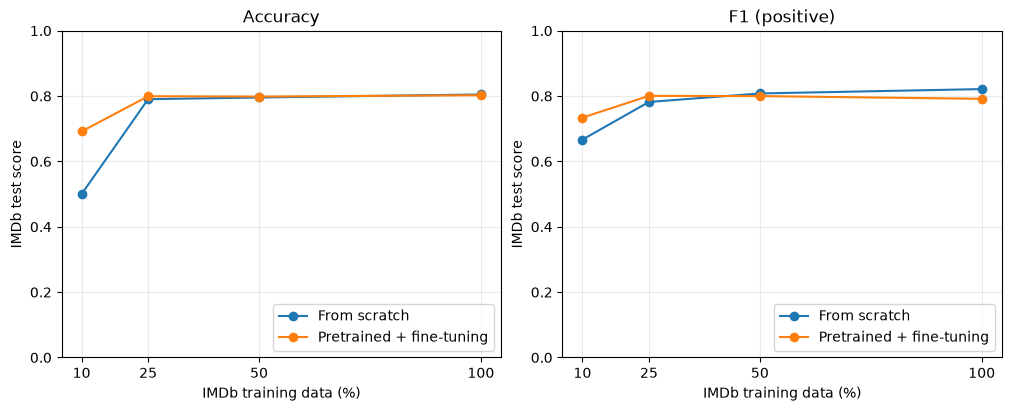

In [4]:
# Cell 5: Mục 16 - Experiment 3: Amount of Training Data
rng = np.random.default_rng(SEED)
train_labels = np.asarray(train["label"])
by_class = [rng.permutation(np.flatnonzero(train_labels == label)) for label in LABELS]

experiment_3 = []
membership = []
for percent in (10, 25, 50, 100):
    subset_size = round(len(train) * percent / 100)
    negative_count = len(by_class[0]) * percent // 100
    positive_count = subset_size - negative_count
    indices = np.sort(np.concatenate([
        by_class[0][:negative_count], by_class[1][:positive_count]
    ]))
    membership.append(pd.DataFrame({
        "target_train_percent": percent,
        "row_id": np.asarray(train["row_id"])[indices],
        "label": train_labels[indices],
    }))
    for condition, prefix, pretrained in (
        ("From scratch", "scratch", False),
        ("Pretrained + fine-tuning", "finetuned", True),
    ):
        run_id = f"{prefix}_{percent}_t128"
        row = run_rows[run_id] if percent == 100 else run_training(
            run_id, pretrained=pretrained, indices=indices
        )
        experiment_3.append(experiment_row(
            3, condition, {"target_train_percent": percent, **row}
        ))

pd.concat(membership, ignore_index=True).to_csv(OUT / "training_subset_manifest.csv", index=False)
efficiency = write_table("experiment3_data_efficiency.csv", experiment_3, columns=[
    "condition", "target_train_percent", "train_examples", *SCORE_COLUMNS, "training_time_s"
])
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
for ax, score, title in zip(axes, ("accuracy", "f1"), ("Accuracy", "F1 (positive)")):
    for condition, rows in efficiency.groupby("condition", sort=False):
        ax.plot(rows["target_train_percent"], rows[score], marker="o", label=condition)
    ax.set(title=title, xlabel="IMDb training data (%)", ylabel="IMDb test score",
           xticks=[10, 25, 50, 100], ylim=(0, 1))
    ax.grid(alpha=0.25)
    ax.legend(loc="lower right")
fig.savefig(LAB_DIR / "data_efficiency.png", dpi=180)
plt.show()
plt.close(fig)

In [5]:
# Cell 6: Mục 17 - Experiment 4: Maximum Sequence Length
experiment_4 = []
for length in (64, 128, 256):
    run_id = f"finetuned_100_t{length}"
    row = run_rows[run_id] if length == MAX_LENGTH else run_training(
        run_id, pretrained=True, length=length
    )
    experiment_4.append(experiment_row(4, f"T = {length}", row))
write_table("experiment4_sequence_length.csv", experiment_4, columns=[
    "max_length", *SCORE_COLUMNS, "training_time_s", "gpu_peak_allocated_mib",
    "cpu_peak_rss_mib", "cpu_peak_above_start_mib"
]);

[transformers] BertModel LOAD REPORT from: google/bert_uncased_L-2_H-128_A-2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
bert.pooler.dense.weight                   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
bert.pooler.dense.bias                     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


finetuned_100_t64 | epoch 1/2 | loss 0.5456 | val F1 0.7727 | train 12.1 s


finetuned_100_t64 | epoch 2/2 | loss 0.3936 | val F1 0.7800 | train 12.2 s


[transformers] BertModel LOAD REPORT from: google/bert_uncased_L-2_H-128_A-2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
bert.pooler.dense.weight                   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
bert.pooler.dense.bias                     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


finetuned_100_t256 | epoch 1/2 | loss 0.4196 | val F1 0.8611 | train 10.9 s


finetuned_100_t256 | epoch 2/2 | loss 0.2388 | val F1 0.8429 | train 11.6 s


,max_length,accuracy,precision,recall,f1,training_time_s,gpu_peak_allocated_mib,cpu_peak_rss_mib,cpu_peak_above_start_mib
0,64,0.76080,0.774457,0.73592,0.754697,24.362306,122.032715,574.761719,0.707031
1,128,0.80248,0.838375,0.74944,0.791417,23.220092,179.521484,822.949219,0.066406
2,256,0.83828,0.783773,0.93432,0.852451,22.469463,301.999023,661.578125,0.246094


In [6]:
# Cell 7: Mục 18 - Experiment 5: Domain Shift
yelp_path = hf_hub_download(
    YELP_ID, "yelp_review_full/test-00000-of-00001.parquet",
    repo_type="dataset", revision=YELP_REVISION,
)
raw_yelp = load_dataset("parquet", data_files={"test": yelp_path}, split="test")
raw_yelp = raw_yelp.add_column("row_id", list(range(len(raw_yelp))))
stars = np.asarray(raw_yelp["label"]) + 1
rng = np.random.default_rng(SEED)
imdb_labels = np.asarray(test["label"])
yelp_indices = np.sort(np.concatenate([
    rng.choice(np.flatnonzero(stars <= 2), size=int((imdb_labels == 0).sum()), replace=False),
    rng.choice(np.flatnonzero(stars >= 4), size=int((imdb_labels == 1).sum()), replace=False),
]))
yelp_test = raw_yelp.select(yelp_indices)
yelp_test = yelp_test.remove_columns("label").add_column(
    "label", (stars[yelp_indices] >= 4).astype(int).tolist()
)
pd.DataFrame({
    "row_id": yelp_test["row_id"], "stars": stars[yelp_indices], "label": yelp_test["label"],
}).to_csv(OUT / "yelp_test_manifest.csv", index=False)

baseline = run_rows["finetuned_100_t128"]
model = SentimentClassifier(pretrained=False).to(DEVICE)
model.load_state_dict(torch.load(
    CHECKPOINTS / f"{baseline['run_id']}.pt", map_location="cpu", weights_only=True
))
yelp_encoded = encode(yelp_test, MAX_LENGTH)
yelp_logits = predict(model, make_loader(yelp_encoded, training=False))
np.save(OUT / "logits_finetuned_100_t128_yelp.npy", yelp_logits.numpy())
del model
yelp_row = {
    **baseline,
    "test_domain": "Yelp",
    "test_examples": len(yelp_test),
    **metrics(yelp_encoded.tensors[-1], yelp_logits.argmax(dim=1)),
}
experiment_5 = [
    experiment_row(5, "In-domain", baseline),
    experiment_row(5, "Out-of-domain", yelp_row),
]
write_table("experiment5_domain_shift.csv", experiment_5, columns=[
    "condition", "test_domain", "test_examples", *SCORE_COLUMNS
]);

,condition,test_domain,test_examples,accuracy,precision,recall,f1
0,In-domain,IMDb,25000,0.80248,0.838375,0.74944,0.791417
1,Out-of-domain,Yelp,25000,0.76940,0.794852,0.72624,0.758998


,test_domain,test_examples,accuracy,precision,recall,f1
0,IMDb,25000,0.80248,0.838375,0.74944,0.791417


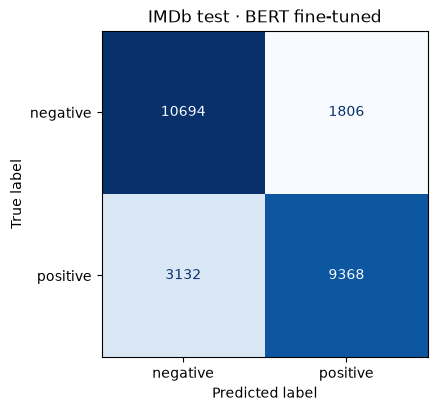

In [7]:
# Cell 8: Mục 19 - Application: Sentiment Classification
imdb_logits = torch.from_numpy(np.load(OUT / f"logits_{baseline['run_id']}_imdb.npy"))
imdb_predictions = imdb_logits.argmax(dim=1).numpy()
application = [
    experiment_row("application", "IMDb sentiment classification", baseline)
]
write_table("application_metrics.csv", application, columns=[
    "test_domain", "test_examples", *SCORE_COLUMNS
])

labels = list(LABELS)
matrix = confusion_matrix(imdb_labels, imdb_predictions, labels=labels)
pd.DataFrame(matrix, index=LABELS.values(), columns=LABELS.values()).to_csv(
    OUT / "confusion_matrix_counts.csv", index_label="true/predicted"
)
fig, ax = plt.subplots(figsize=(5, 4), layout="constrained")
ConfusionMatrixDisplay(matrix, display_labels=list(LABELS.values())).plot(
    ax=ax, cmap="Blues", colorbar=False, values_format="d"
)
ax.set_title("IMDb test · BERT fine-tuned")
fig.savefig(LAB_DIR / "confusion_matrix.png", dpi=180)
plt.show()
plt.close(fig)

In [8]:
# Cell 9: Mục 20 - Export for Manual Error Analysis
probabilities = torch.softmax(imdb_logits, dim=1)
confidence = probabilities.max(dim=1).values.numpy()
predictions = pd.DataFrame({
    "row_id": test["row_id"],
    "text": test["text"],
    "true": [LABELS[label] for label in imdb_labels],
    "pred": [LABELS[label] for label in imdb_predictions],
    "p_negative": probabilities[:, 0].numpy(),
    "p_positive": probabilities[:, 1].numpy(),
    "confidence": confidence,
    "correct": imdb_predictions == imdb_labels,
})
HIGH_LIMIT = 0.80
errors = predictions.loc[~predictions["correct"]].copy()
errors["confusion_case"] = np.where(errors["pred"].eq("positive"), "FP", "FN")
errors["error_type"] = ""
errors["hypothesis"] = ""
errors = errors.sort_values(["confidence", "row_id"], ascending=[False, True])
errors.to_csv(OUT / "error_candidates.csv", index=False, encoding="utf-8-sig")

counts = errors["confusion_case"].value_counts().reindex(["FP", "FN"], fill_value=0)
counts.rename("count").to_csv(OUT / "error_counts.csv", index_label="confusion_case")
display(counts.to_frame("count"))

high_confidence = errors.loc[errors["confidence"] >= HIGH_LIMIT].head(2)
remaining = errors.drop(index=high_confidence.index)
false_positives = remaining.loc[remaining["confusion_case"] == "FP"].head(3)
false_negatives = remaining.loc[remaining["confusion_case"] == "FN"].head(3)
examples = pd.concat([
    false_positives.assign(sample_group="FP"),
    false_negatives.assign(sample_group="FN"),
    high_confidence.assign(sample_group="High-confidence error"),
], ignore_index=True)[[
    "sample_group", "row_id", "text", "true", "pred", "confidence",
    "confusion_case", "error_type", "hypothesis",
]]
examples.to_csv(OUT / "error_examples.csv", index=False, encoding="utf-8-sig")

if len(examples) < 8:
    print("The test predictions contain fewer than eight distinct examples meeting the quotas.")

# Show a text preview in the notebook and keep the full review in the CSV.
text_preview = examples["text"].str.slice(0, 200)
text_preview = text_preview.mask(examples["text"].str.len() > 200, text_preview + "…")
with pd.option_context("display.max_colwidth", None):
    display(examples.assign(text=text_preview, confidence=examples["confidence"].round(4)))


,count
confusion_case,
FP,1806
FN,3132


,sample_group,row_id,text,true,pred,confidence,confusion_case,error_type,hypothesis
0,FP,12025,"Jack Lemmon was one of our great actors. His performances in Days Of Wine And Roses, The Apartment, Some Like It Hot, Missing (to name the first ones that come to mind) were all worthy of Best Actor n…",negative,positive,0.9950,FP,,
1,FP,3553,"This film has the language, the style and the attitude down ... plus greats rides from Occy (a world champ) and the great Jerry Lopez. John Philbin as Turtle has the surf pidgin down, and the surfing …",negative,positive,0.9948,FP,,
2,FP,4118,This is definitely one of the best Kung fu movies in the history of Cinema. The screenplay is really well done (which is not often the case for this type of movies) and you can see that Chuck (in one …,negative,positive,0.9946,FP,,
3,FN,14082,"In defense of this movie I must repeat what I had stated previously. The movie is called Arachina, it has a no name cast and I do not mean no name as in actors who play in little seen art house films.…",positive,negative,0.9952,FN,,
4,FN,15026,"Emilio Estevez actually directed a good movie--who woulda thought? I sat through two previous films Estevez directed--""Wisdom"" (with then girlfriend Demi Moore) and ""Men at Work"" (with brother Charlie…",positive,negative,0.9948,FN,,
5,FN,24981,"""Gaming? Nicotine? Fisticuffs? We're moving in a descending spiral of iniquity!"" So says the head of St. Swithen's upon inspecting the master's common at Nutbourne. The faculty and students of St. Swi…",positive,negative,0.9947,FN,,
6,High-confidence error,18193,"I swore I would never allow myself to devolve into to the bogus authority figures of the sixties who told me things were better in the ""good old days""  the current Australian Prime Minister is a sord…",positive,negative,0.9955,FN,,
7,High-confidence error,6979,"Let me say this about Edward D. Wood Jr. He had a passion for his work that I wish more people did have. If we all had the optimism and the commanding hope of Ed Wood, the world would probably be a mu…",negative,positive,0.9953,FP,,


,total,correct,incorrect,accuracy
confidence_group,,,,
Low,2000,1066,934,0.533000
Medium,4809,3013,1796,0.626534
High,18191,15983,2208,0.878621


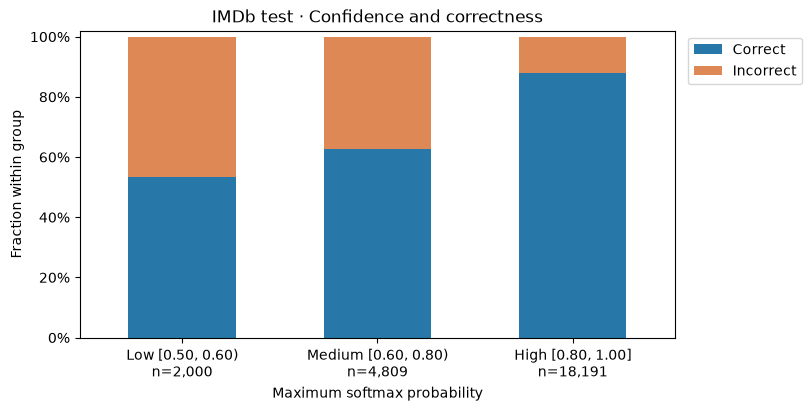

In [9]:
# Cell 10: Mục 21 - Confidence Analysis
LOW_LIMIT = 0.60
levels = ["Low", "Medium", "High"]
predictions["confidence_group"] = pd.cut(
    predictions["confidence"], bins=[0.5, LOW_LIMIT, HIGH_LIMIT, np.inf],
    labels=levels, right=False,
)
summary = predictions.groupby("confidence_group", observed=False)["correct"].agg(
    total="size", correct="sum"
)
summary["incorrect"] = summary["total"] - summary["correct"]
summary["accuracy"] = summary["correct"] / summary["total"].replace(0, np.nan)
summary.to_csv(OUT / "confidence_summary.csv", index_label="confidence_group")
predictions.to_csv(OUT / "imdb_test_predictions.csv", index=False, encoding="utf-8-sig")
display(summary)

fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
plot_rows = summary[["correct", "incorrect"]].div(summary["total"], axis=0).fillna(0)
plot_rows.rename(columns={"correct": "Correct", "incorrect": "Incorrect"}).plot.bar(
    ax=ax, stacked=True, rot=0, color=["#2778A8", "#DD8855"], width=0.55
)
ax.set(
    xlabel="Maximum softmax probability",
    ylabel="Fraction within group",
    title="IMDb test · Confidence and correctness",
    xticks=range(len(levels)),
    xticklabels=[
        f"Low [0.50, {LOW_LIMIT:.2f})\nn={summary.loc['Low', 'total']:,}",
        f"Medium [{LOW_LIMIT:.2f}, {HIGH_LIMIT:.2f})\nn={summary.loc['Medium', 'total']:,}",
        f"High [{HIGH_LIMIT:.2f}, 1.00]\nn={summary.loc['High', 'total']:,}",
    ],
    ylim=(0, 1.02),
)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
fig.savefig(LAB_DIR / "confidence_analysis.png", dpi=180)
plt.show()
plt.close(fig)

In [10]:
# Cell 11: Mục 22 - Ablation: Frozen vs Fine-Tuned
ablation = [
    {"experiment": "ablation", **{k: v for k, v in row.items() if k != "experiment"}}
    for row in experiment_2
]
write_table("ablation_frozen_vs_finetuned.csv", ablation, columns=[
    "condition", "encoder_trainable", "train_examples", "max_length", "epochs",
    "accuracy", "f1", "training_time_s", "trainable_parameters"
]);

,condition,encoder_trainable,train_examples,max_length,epochs,accuracy,f1,training_time_s,trainable_parameters
0,Frozen,False,22500,128,2,0.69044,0.697542,12.343728,258
1,Fine-tuning,True,22500,128,2,0.80248,0.791417,23.220092,4369666


In [11]:
# Cell 12: Mục 23 - Reproducibility
report = {
    "model": MODEL_ID,
    "model_revision": MODEL_REVISION,
    "tokenizer": MODEL_ID,
    "tokenizer_revision": MODEL_REVISION,
    "datasets": {
        "imdb": {"name": IMDB_ID, "revision": IMDB_REVISION},
        "yelp": {
            "name": YELP_ID, "revision": YELP_REVISION, "source_split": "test",
            "test_examples": len(yelp_test), "negative_stars": [1, 2], "positive_stars": [4, 5],
            "excluded_stars": [3],
        },
    },
    "imdb_splits": {
        "train": {"source": "train", "fraction": 0.9, "rows": len(train)},
        "validation": {"source": "train", "fraction": 0.1, "rows": len(validation)},
        "test": {"source": "test", "fraction": 1.0, "rows": len(test)},
        "stratify_by": "label",
        "manifest": "imdb_split_manifest.csv",
    },
    "label_mapping": LABELS,
    "sequence_lengths": [64, 128, 256],
    "baseline_max_length": MAX_LENGTH,
    "padding": "fixed to max_length",
    "batch_size": BATCH_SIZE,
    "eval_batch_size": EVAL_BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "epochs": EPOCHS,
    "optimizer": "AdamW",
    "weight_decay": WEIGHT_DECAY,
    "seed": SEED,
    "device": str(DEVICE),
    "gpu": torch.cuda.get_device_name() if DEVICE.type == "cuda" else None,
    "cpu": platform.processor() or platform.machine(),
    "ram_gib": round(psutil.virtual_memory().total / 1024 ** 3, 2),
    "precision": "bf16 autocast" if USE_BF16 else "float32",
    "checkpoint_selection": "highest validation F1, first epoch on ties",
    "metric_average": "binary, positive label = 1",
    "training_time_definition": "sum of training epoch times, excluding validation, testing, and checkpoint I/O",
    "gpu_memory_definition": "peak CUDA memory allocated by PyTorch during a training epoch",
    "cpu_memory_definition": "process RSS sampled every 50 ms during training, including start and end",
    "training_time_s": {key: row["training_time_s"] for key, row in run_rows.items()},
    "confidence_boundaries": {"medium_from": LOW_LIMIT, "high_from": HIGH_LIMIT},
    "python": platform.python_version(),
    "packages": {name: version(name) for name in (
        "torch", "transformers", "datasets", "huggingface_hub", "scikit-learn",
        "numpy", "pandas", "matplotlib", "psutil",
    )},
}
formatted = json.dumps(report, indent=2)
(OUT / "reproducibility.json").write_text(formatted + "\n", encoding="utf-8")
print(formatted)

{
  "model": "google/bert_uncased_L-2_H-128_A-2",
  "model_revision": "30b0a37ccaaa32f332884b96992754e246e48c5f",
  "tokenizer": "google/bert_uncased_L-2_H-128_A-2",
  "tokenizer_revision": "30b0a37ccaaa32f332884b96992754e246e48c5f",
  "datasets": {
    "imdb": {
      "name": "stanfordnlp/imdb",
      "revision": "e6281661ce1c48d982bc483cf8a173c1bbeb5d31"
    },
    "yelp": {
      "name": "Yelp/yelp_review_full",
      "revision": "c1f9ee939b7d05667af864ee1cb066393154bf85",
      "source_split": "test",
      "test_examples": 25000,
      "negative_stars": [
        1,
        2
      ],
      "positive_stars": [
        4,
        5
      ],
      "excluded_stars": [
        3
      ]
    }
  },
  "imdb_splits": {
    "train": {
      "source": "train",
      "fraction": 0.9,
      "rows": 22500
    },
    "validation": {
      "source": "train",
      "fraction": 0.1,
      "rows": 2500
    },
    "test": {
      "source": "test",
      "fraction": 1.0,
      "rows": 25000
    },
 

In [12]:
# Cell 13: Mục 25 - Deliverables: Consolidated Results
results = pd.DataFrame(
    experiment_1 + experiment_2 + experiment_3 + experiment_4
    + experiment_5 + application + ablation
)
results.to_csv(LAB_DIR / "results.csv", index=False, float_format="%.8g")
display(results[[
    "experiment", "condition", "run_id", "test_domain", "train_percent", "max_length",
    "accuracy", "precision", "recall", "f1", "training_time_s", "parameters",
    "gpu_peak_allocated_mib", "cpu_peak_rss_mib",
]])

,experiment,condition,run_id,test_domain,train_percent,max_length,accuracy,precision,recall,f1,training_time_s,parameters,gpu_peak_allocated_mib,cpu_peak_rss_mib
0,1,Transformer from scratch,scratch_100_t128,IMDb,100.0,128,0.80480,0.757432,0.89680,0.821245,27.926857,4369666,179.521484,1212.058594
1,1,Pretrained + fine-tuning,finetuned_100_t128,IMDb,100.0,128,0.80248,0.838375,0.74944,0.791417,23.220092,4369666,179.521484,822.949219
2,2,Frozen,frozen_100_t128,IMDb,100.0,128,0.69044,0.681898,0.71392,0.697542,12.343728,4369666,64.034668,545.230469
3,2,Fine-tuning,finetuned_100_t128,IMDb,100.0,128,0.80248,0.838375,0.74944,0.791417,23.220092,4369666,179.521484,822.949219
4,3,From scratch,scratch_10_t128,IMDb,10.0,128,0.50000,0.500000,1.00000,0.666667,2.408699,4369666,179.521484,533.984375
5,3,Pretrained + fine-tuning,finetuned_10_t128,IMDb,10.0,128,0.69160,0.645381,0.85056,0.733899,2.492180,4369666,179.521484,530.496094
6,3,From scratch,scratch_25_t128,IMDb,25.0,128,0.79036,0.814815,0.75152,0.781889,6.257913,4369666,179.521484,534.203125
7,3,Pretrained + fine-tuning,finetuned_25_t128,IMDb,25.0,128,0.79940,0.796248,0.80472,0.800462,6.106618,4369666,179.521484,550.343750
8,3,From scratch,scratch_50_t128,IMDb,50.0,128,0.79552,0.761837,0.85984,0.807877,11.751284,4369666,179.521484,539.250000
9,3,Pretrained + fine-tuning,finetuned_50_t128,IMDb,50.0,128,0.79844,0.794320,0.80544,0.799841,12.673764,4369666,179.521484,550.609375
